In [1]:
import sys
sys.path.append('..')

In [2]:
from src import SV_configs
from src import utils
from src import linear_RNN
from pathlib import Path
import numpy as np
from types import SimpleNamespace
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

In [10]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

In [6]:
args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 7,
    'num_samples' : 50,
    'num_epochs' : 500,
    'lr' : 5,
    'initialization_scale' : 1e-1,
    'input_size' : 3,
    'hidden_size' : 3,
    'output_size' : 3,
    'S_config': ['inverse_exponential','inverse_exponential','exponential'],
    'delta' : [1.1,0.5,0.5], 
    'lambda_0' : [0.5,1.1,1.1], 
    'S_T' : [1,1,1],
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.01,0.01,0.01], 
    'in_mode_init' : [0.1,0.1,0.1],
    'out_mode_init': [0.1,0.1,0.1], 
    'rec_mode_init': [0.01,0.01,0.01],
    'num_SV' : 3,
    'aligned_student_weights': True,
    'log_H': False,
    'log_y_hat': True,
    'compute_NTK': True,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 1,
    'subsample_NTK': False,
    'eigenspace_dynamics': False,
    'task_dynamics': 'diagonalized',
    'subsample_H': True,
    'theta': None
}
args = SimpleNamespace(**args)

In [8]:
args.S = SV_configs.create_SV_trajectories(args)
data_path = Path(args.data_out_dir) / args.name

In [9]:
data_tape = utils.get_data_tape(args)
tape = utils.get_tape_module(args)
seed = 0
utils.set_seeds(seed)
data_tape = utils.generate_data_multiseed(args, data_tape, seed) 
tape = utils.initialize_student_multiseed(args, data_tape, seed, tape)
model = linear_RNN.LinearRNN_multiseed(args, tape, seed)
model.train(data_tape.X[seed], data_tape.y[seed]) 
model.project_SVD_space(data_tape)
tape = model.tape

/Users/alex/Documents/Research/LinearRNNLearningDynamics/LRNN_dynamics/figure_notebooks copy/../src/linear_RNN.py:13: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /private/var/folders/k1/30mswbxs7r1g6zwn8y4fyt500000gp/T/abs_5ae0635zuj/croot/pytorch-select_1700511177724/work/aten/src/ATen/native/Copy.cpp:299.)
  self.W_x = torch.tensor(copy.deepcopy(tape.W_x[seed][0]), dtype=torch.float64)


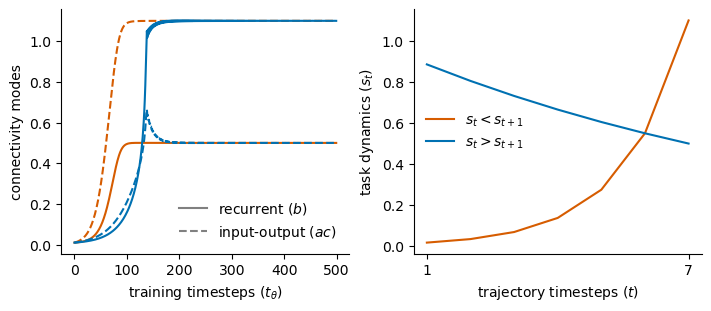

In [15]:
fig = plt.figure(figsize=(7,3), layout='constrained') #plt.figure(figsize=(s*TEXTWIDTH*.65, s*PAGEHEIGHT*0.14), layout='constrained')
mosaic = """
ad
"""
axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

axd['a'].plot(tape.recurrent_modes[seed,:,0], color=blind_colors[0],label=r'$s_t<s_{t+1}$')
axd['a'].plot(tape.input_output_modes[seed,:,0], color=blind_colors[0], ls='dashed')
axd['a'].plot(tape.recurrent_modes[seed,:,1], color=blind_colors[1],label=r'$s_t>s_{t+1}$')
axd['a'].plot(tape.input_output_modes[seed,:,1], color=blind_colors[1], ls='dashed')
axd['a'].set_xlabel(r'training timesteps ($t_\theta$)')
axd['a'].set_ylabel(r'connectivity modes')

handles, labels = plt.gca().get_legend_handles_labels()
line_1 = Line2D([0], [0], label=r'recurrent ($b$)', color='gray')
line_2 = Line2D([0], [0], label=r'input-output ($ac$)', color='gray', ls='dashed')
handles = [line_1, line_2]
axd['a'].legend(frameon=False, handles=handles)#, bbox_to_anchor=(0.65, -0.05))

axd['d'].plot(range(1,8), args.S[:,0,0], color=blind_colors[0],label=r'$s_t<s_{t+1}$')
axd['d'].plot(range(1,8), args.S[:,1,1], color=blind_colors[1],label=r'$s_t>s_{t+1}$')
axd['d'].set_xlabel(r'trajectory timesteps ($t$)')
axd['d'].set_ylabel(r'task dynamics ($s_t$)')
axd['d'].set_xticks([1, 7])
axd['d'].legend(frameon=False)
# fig.savefig('paper_figs/large_and_later_SV.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/larger_and_later_SV.png', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/larger_and_later_SV.pdf', dpi=300, transparent=True, bbox_inches='tight')

In [16]:
error = 0.5 - tape.recurrent_modes[seed,:,0]

e1 = 0
alpha = 0
for i in range(1, args.trajectory_length+1):
    e1 += (args.S[i-1,alpha,alpha] - tape.input_output_modes[seed,:,alpha]*(tape.recurrent_modes[seed,:,alpha])**(args.trajectory_length - i))
    
e2 = 0
alpha = 1
for i in range(1, args.trajectory_length+1):
    e2 += (args.S[i-1,alpha,alpha] - tape.input_output_modes[seed,:,alpha]*(tape.recurrent_modes[seed,:,alpha])**(args.trajectory_length - i))

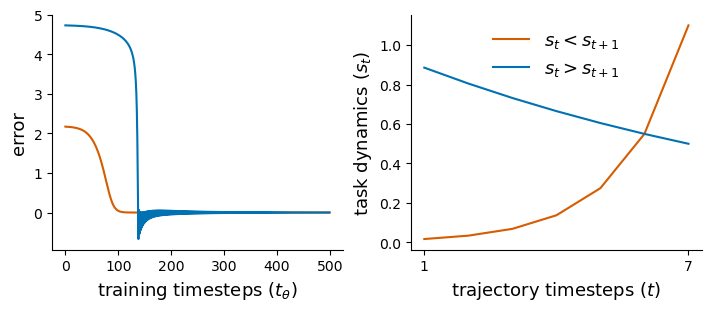

In [17]:
fig = plt.figure(figsize=(7,3), layout='constrained')
mosaic = """
ad
"""
axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

error_1 = (0.5 - tape.recurrent_modes[seed,:,0]) + (1.1 - tape.input_output_modes[seed,:,0])
error_2 = (1.1 - tape.recurrent_modes[seed,:,1]) + (0.5 - tape.input_output_modes[seed,:,1])
axd['a'].plot(e1, color=blind_colors[0],label=r'$s_t<s_{t+1}$')
axd['a'].plot(e2, color=blind_colors[1],label=r'$s_t>s_{t+1}$')
axd['a'].set_xlabel(r'training timesteps ($t_\theta$)',fontsize=13)
axd['a'].set_ylabel(r'error',fontsize=13)

axd['d'].plot(range(1,8), args.S[:,0,0], color=blind_colors[0],label=r'$s_t<s_{t+1}$')
axd['d'].plot(range(1,8), args.S[:,1,1], color=blind_colors[1],label=r'$s_t>s_{t+1}$')
axd['d'].set_xlabel(r'trajectory timesteps ($t$)',fontsize=13)
axd['d'].set_ylabel(r'task dynamics ($s_t$)',fontsize=13)
axd['d'].set_xticks([1, 7])
axd['d'].legend(frameon=False,fontsize=13)
# fig.savefig('paper_figs/large_and_later_SV_error.svg', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/larger_and_later_SV_error.png', dpi=300, transparent=True, bbox_inches='tight')
# fig.savefig('paper_figs/larger_and_later_SV_error.pdf', dpi=300, transparent=True, bbox_inches='tight')